# Computational Thermofluid Dynamics - Chapter 3

Technical University of Munich, Professur für Thermofluiddynamik - Pr. Polifke

Created: 04/2024 | J. Yao, N. Garcia, G. Varillon

==============================================================================================

# Initialization
Initialize all the geometric and physical parameters

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple


In [67]:
# --------------------------------------------------------------------------
def formfunction(x: np.ndarray | float,
                 shape: str,
                 H1: float,
                 H2: float,
                 L:  float) -> np.ndarray | float:
    """Profile of the moving / curved top wall."""
    if shape == 'linear':
        return (H1/2) + (H2/2 - H1/2) * (x / L)
    elif shape == 'rectangular':
        return (H1/2) * np.ones_like(x)
    elif shape == 'quadratic':
        a = (H1/2 - H2/2) / L**2
        return a * (x - L)**2 + H2/2
    elif shape == 'crazy':
        return (H1/2 - H2/2) * np.sin(np.pi * x / L) + (H1 + H2) / 4
    else:
        raise ValueError(f'Unknown shape: {shape}')

# --------------------------------------------------------------------------
def setUpMesh(M: int,
              H1: float,
              H2: float,
              L:  float,
              shape: str
             ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Structured 2-D mesh with 

      X, Y       → cell centres + one ghost layer      (0 … M+1 each axis)
      X_cor, Y_cor → vertices (nodes)                  (0 … M   each axis)
    """

    # ── 1. build the vertex grid (X_cor, Y_cor) ───────────────────────────
    x_nodes        = np.linspace(0.0, L, M + 1)          # i-direction
    X_cor          = np.zeros((M + 1, M + 1))            # (i , j)
    Y_cor          = np.zeros_like(X_cor)

    for i, xi in enumerate(x_nodes):
        top_y      = formfunction(xi, shape, H1, H2, L)
        y_nodes    = np.linspace(0.0, top_y, M + 1)      # j-direction
        X_cor[i, :] = xi
        Y_cor[i, :] = y_nodes

    # ── 2. allocate cell-centre arrays (X, Y) ─────────────────────────────
    X = np.zeros((M + 2, M + 2))
    Y = np.zeros_like(X)

    # interior centres: i = 1…M , j = 1…M
    X[1:M+1, 1:M+1] = 0.25 * (X_cor[:-1, :-1] + X_cor[1:, :-1] +
                              X_cor[1:,  1:]  + X_cor[:-1, 1:])
    Y[1:M+1, 1:M+1] = 0.25 * (Y_cor[:-1, :-1] + Y_cor[1:, :-1] +
                              Y_cor[1:,  1:]  + Y_cor[:-1, 1:])

    # ── 3. ghost columns (west & east) ────────────────────────────────────
    X[1:M+1, 0]     = 0.5 * (X_cor[:-1, 0]   + X_cor[1:, 0])
    Y[1:M+1, 0]     = 0.5 * (Y_cor[:-1, 0]   + Y_cor[1:, 0])
    X[1:M+1, M+1]   = 0.5 * (X_cor[:-1, -1]  + X_cor[1:, -1])
    Y[1:M+1, M+1]   = 0.5 * (Y_cor[:-1, -1]  + Y_cor[1:, -1])

    # ── 4. ghost rows (south & north) ─────────────────────────────────────
    X[0,   1:M+1]   = 0.5 * (X_cor[0, :-1]   + X_cor[0, 1:])
    Y[0,   1:M+1]   = 0.5 * (Y_cor[0, :-1]   + Y_cor[0, 1:])
    X[M+1, 1:M+1]   = 0.5 * (X_cor[-1, :-1]  + X_cor[-1, 1:])
    Y[M+1, 1:M+1]   = 0.5 * (Y_cor[-1, :-1]  + Y_cor[-1, 1:])

    # ── 5. ghost corners ─────────────────────────────────────────────────
    X[0,   0]   = X_cor[0,   0] ;  Y[0,   0]   = Y_cor[0,   0]
    X[0,  -1]   = X_cor[0,  -1] ;  Y[0,  -1]   = Y_cor[0,  -1]
    X[-1, 0]    = X_cor[-1, 0]  ;  Y[-1, 0]    = Y_cor[-1, 0]
    X[-1, -1]   = X_cor[-1, -1] ;  Y[-1, -1]   = Y_cor[-1, -1]

    return X, Y, X_cor, Y_cor


In [68]:
class Coordicate2D():
    def __init__(self, x, y):
        self.x = x
        self.y = y

        

In [69]:
class SimpleFields2D:
    """
    Initialize the system and set the north ghost cell value
    """
    def __init__(self, X, Y, X_cor, Y_cor, rho0=1.0, mu0=1.0):
        self.X = X
        self.Y = Y
        self.X_cor = X_cor
        self.Y_cor = Y_cor  
        self.m, self.n = X.shape
        # Predefined fields
        self.U = np.zeros((self.m, self.n))
        self.V = np.zeros((self.m, self.n))
        self.P = np.zeros((self.m, self.n))
        self.p_prime = np.zeros((self.m, self.n))  
        self.mu = np.full((self.m, self.n), mu0)
        self.rho = np.full((self.m, self.n), rho0)

        # Set north lid velocity
        self.U[:, self.n - 1] = 1.0
        
        # Generic dictionary for additional fields (e.g., phi, T, Z)
        self.vars = {}
        
    def add_field(self, name, initial=0.0):
        self.vars[name] = np.full((self.m, self.n), initial)
    def get_field(self, name):
        return self.vars[name]


In [70]:
class Stencil2D:
    """
    2-D finite-volume stencil that assumes:

      * X[i,j], Y[i,j]  – cell-centre coordinates
      * i increases ➜ east  (x-direction)
      * j increases ➜ north (y-direction)
      * ghost cells are the outermost layer:
          i = 0 or nx-1 ,  j = 0 or ny-1
      * interior cells are
          i = 1 … nx-2 ,  j = 1 … ny-2
    """
    def __init__(self, X, Y):
        self.X = X
        self.Y = Y
        self.nx, self.ny = X.shape   

    # ── cell classification ────────────────────────────────────────────
    def cell_type(self, i: int, j: int) -> str:
        if   0 < i < self.nx - 1 and 0 < j < self.ny - 1:
            return 'interior'

        # north boundary (j = ny-1)
        elif j == self.ny - 1:
            if   i == 0:            return 'NW'
            elif i == self.nx - 1:  return 'NE'
            else:                   return 'north'

        # south boundary (j = 0)
        elif j == 0:
            if   i == 0:            return 'SW'
            elif i == self.nx - 1:  return 'SE'
            else:                   return 'south'

        # west / east boundaries
        elif i == 0:                return 'west'
        elif i == self.nx - 1:      return 'east'

        raise ValueError(f"Unexpected cell indices: ({i},{j})")

    # ── neighbour lookup ───────────────────────────────────────────────
    def get_neighbors(self, i: int, j: int) -> dict:
        """
        Returns a dict with keys 'N','S','E','W' – only for neighbors that
        lie *inside* the array bounds.
        """
        nbr = {}
        if i > 0:               nbr['W'] = (i - 1, j)          # west
        if i < self.nx - 1:     nbr['E'] = (i + 1, j)          # east
        if j > 0:               nbr['S'] = (i, j - 1)          # south
        if j < self.ny - 1:     nbr['N'] = (i, j + 1)          # north
        return nbr

    # ── face-centre coordinates ────────────────────────────────────────
    def get_face_centers(self, i: int, j: int) -> dict:
        """
        Returns {'N': Coordicate2D, 'S': …, 'E': …, 'W': …}
        for every face that actually exists.
        """
        faces   = {}
        Pc      = Coordicate2D(self.X[i, j], self.Y[i, j])
        for d, (ni, nj) in self.get_neighbors(i, j).items():
            Nc = Coordicate2D(self.X[ni, nj], self.Y[ni, nj])
            faces[d] = Coordicate2D(0.5 * (Pc.x + Nc.x),
                                    0.5 * (Pc.y + Nc.y))
        return faces


In [71]:
class FVM_grad:
    """
    Finite Volume Method gradient operator for a scalar field phi.
    Computes the gradient at cell centers using face-interpolated values
    and Euclidean face center distances.
    """
    def __init__(self, X, Y, X_cor, Y_cor, stencil: Stencil2D):
        self.X = X
        self.Y = Y
        self.m, self.n = X.shape
        self.stencil = stencil
        self.X_cor = X_cor
        self.Y_cor = Y_cor

    def compute_gradient(self, phi):
        grad_x = np.zeros((self.m, self.n))
        grad_y = np.zeros((self.m, self.n))

        for i in range(1, self.m-1):
            for j in range(1, self.n-1):
                neighbors = self.stencil.get_neighbors(i, j)
                faces     = self.stencil.get_face_centers(i, j)
                ctype     = self.stencil.cell_type(i, j)

                if ctype == 'interior':
                    ie, je = neighbors['E']
                    iw, jw = neighbors['W']
                    in_, jn = neighbors['N']
                    is_, js = neighbors['S']
                    x1, y1 = self.X_cor[i-1   , j], self.Y_cor[i-1   , j]
                    x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                    dx = np.hypot(x2 - x1, y2 - y1)
                    x3, y3 = self.X_cor[i   , j-1], self.Y_cor[i   , j-1]
                    x4, y4 = self.X_cor[i , j], self.Y_cor[i , j ]
                    dy = np.hypot(x4 - x3, y4 - y3)
                    phi_e = 0.5 * (phi[i, j] + phi[ie, je])
                    phi_w = 0.5 * (phi[i, j] + phi[iw, jw])
                    phi_n = 0.5 * (phi[i, j] + phi[in_, jn])
                    phi_s = 0.5 * (phi[i, j] + phi[is_, js])
                    grad_x[i, j] = (phi_e - phi_w) / dx
                    grad_y[i, j] = (phi_n - phi_s) / dy

                # elif ctype == 'east':
                #     # Only has W, N, S neighbors
                #     iw, jw = neighbors['W']
                #     in_, jn = neighbors['N']
                #     is_, js = neighbors['S']
                #     w = faces['W']
                #     n = faces['N']
                #     s = faces['S']
                #     phi_w = 0.5 * (phi[i, j] + phi[iw, jw])
                #     phi_n = 0.5 * (phi[i, j] + phi[in_, jn])
                #     phi_s = 0.5 * (phi[i, j] + phi[is_, js])
                #     dx = np.hypot(self.X[i, j] - w.x, self.Y[i, j] - w.y)
                #     dy = np.hypot(n.x - s.x, n.y - s.y)
                #     grad_x[i, j] = (phi[i, j] - phi_w) / dx
                #     grad_y[i, j] = (phi_n - phi_s) / dy

                # elif ctype == 'west':
                #     # Only has E, N, S neighbors
                #     ie, je = neighbors['E']
                #     in_, jn = neighbors['N']
                #     is_, js = neighbors['S']
                #     e = faces['E']
                #     n = faces['N']
                #     s = faces['S']
                #     phi_e = 0.5 * (phi[i, j] + phi[ie, je])
                #     phi_n = 0.5 * (phi[i, j] + phi[in_, jn])
                #     phi_s = 0.5 * (phi[i, j] + phi[is_, js])
                #     dx = np.hypot(e.x - self.X[i, j], e.y - self.Y[i, j])
                #     dy = np.hypot(n.x - s.x, n.y - s.y)
                #     grad_x[i, j] = (phi_e - phi[i, j]) / dx
                #     grad_y[i, j] = (phi_n - phi_s) / dy

                # elif ctype == 'north':
                #     # Only has S, E, W neighbors
                #     is_, js = neighbors['S']
                #     ie, je = neighbors['E']
                #     iw, jw = neighbors['W']
                #     s = faces['S']
                #     e = faces['E']
                #     w = faces['W']
                #     phi_s = 0.5 * (phi[i, j] + phi[is_, js])
                #     phi_e = 0.5 * (phi[i, j] + phi[ie, je])
                #     phi_w = 0.5 * (phi[i, j] + phi[iw, jw])
                #     dy = np.hypot(self.X[i, j] - s.x, self.Y[i, j] - s.y)
                #     dx = np.hypot(e.x - w.x, e.y - w.y)
                #     grad_x[i, j] = (phi_e - phi_w) / dx
                #     grad_y[i, j] = (phi[i, j] - phi_s) / dy

                # elif ctype == 'south':
                #     # Only has N, E, W neighbors
                #     in_, jn = neighbors['N']
                #     ie, je = neighbors['E']
                #     iw, jw = neighbors['W']
                #     n = faces['N']
                #     e = faces['E']
                #     w = faces['W']
                #     phi_n = 0.5 * (phi[i, j] + phi[in_, jn])
                #     phi_e = 0.5 * (phi[i, j] + phi[ie, je])
                #     phi_w = 0.5 * (phi[i, j] + phi[iw, jw])
                #     dy = np.hypot(n.x - self.X[i, j], n.y - self.Y[i, j])
                #     dx = np.hypot(e.x - w.x, e.y - w.y)
                #     grad_x[i, j] = (phi_e - phi_w) / dx
                #     grad_y[i, j] = (phi_n - phi[i, j]) / dy

                # elif ctype == 'NE':
                #     # Only W and S neighbors
                #     iw, jw = neighbors['W']
                #     is_, js = neighbors['S']
                #     w = faces['W']
                #     s = faces['S']
                #     phi_w = 0.5 * (phi[i, j] + phi[iw, jw])
                #     phi_s = 0.5 * (phi[i, j] + phi[is_, js])
                #     dx = np.hypot(self.X[i, j] - w.x, self.Y[i, j] - w.y)
                #     dy = np.hypot(self.X[i, j] - s.x, self.Y[i, j] - s.y)
                #     grad_x[i, j] = (phi[i, j] - phi_w) / dx
                #     grad_y[i, j] = (phi[i, j] - phi_s) / dy

                # elif ctype == 'NW':
                #     # Only E and S neighbors
                #     ie, je = neighbors['E']
                #     is_, js = neighbors['S']
                #     e = faces['E']
                #     s = faces['S']
                #     phi_e = 0.5 * (phi[i, j] + phi[ie, je])
                #     phi_s = 0.5 * (phi[i, j] + phi[is_, js])
                #     dx = np.hypot(e.x - self.X[i, j], e.y - self.Y[i, j])
                #     dy = np.hypot(self.X[i, j] - s.x, self.Y[i, j] - s.y)
                #     grad_x[i, j] = (phi_e - phi[i, j]) / dx
                #     grad_y[i, j] = (phi[i, j] - phi_s) / dy

                # elif ctype == 'SE':
                #     # Only W and N neighbors
                #     iw, jw = neighbors['W']
                #     in_, jn = neighbors['N']
                #     w = faces['W']
                #     n = faces['N']
                #     phi_w = 0.5 * (phi[i, j] + phi[iw, jw])
                #     phi_n = 0.5 * (phi[i, j] + phi[in_, jn])
                #     dx = np.hypot(self.X[i, j] - w.x, self.Y[i, j] - w.y)
                #     dy = np.hypot(n.x - self.X[i, j], n.y - self.Y[i, j])
                #     grad_x[i, j] = (phi[i, j] - phi_w) / dx
                #     grad_y[i, j] = (phi_n - phi[i, j]) / dy

                # elif ctype == 'SW':
                #     # Only E and N neighbors
                #     ie, je = neighbors['E']
                #     in_, jn = neighbors['N']
                #     e = faces['E']
                #     n = faces['N']
                #     phi_e = 0.5 * (phi[i, j] + phi[ie, je])
                #     phi_n = 0.5 * (phi[i, j] + phi[in_, jn])
                #     dx = np.hypot(e.x - self.X[i, j], e.y - self.Y[i, j])
                #     dy = np.hypot(n.x - self.X[i, j], n.y - self.Y[i, j])
                #     grad_x[i, j] = (phi_e - phi[i, j]) / dx
                #     grad_y[i, j] = (phi_n - phi[i, j]) / dy

                else:
                    grad_x[i, j] = 0.0
                    grad_y[i, j] = 0.0

        return grad_x, grad_y


In [72]:
class FVM_div:
    """
    FV face-flux operator for (ρ u φ) on the indexing:

        i = 0 ...... west   →  increasing i goes east
        j = 0 ...... east   →  increasing j goes north

        We specify impenetrable wall for all the boundaries

    """
    def __init__(self, X, Y, X_cor, Y_cor, stencil):
        self.X        = X              # cell centres
        self.Y        = Y
        self.X_cor    = X_cor          # cell-corner coordinates
        self.Y_cor    = Y_cor
        self.m, self.n = X.shape
        self.stencil  = stencil

    # ---------------------------------------------------------------
    def compute_face_fluxes(self, phi, U, V, rho):
        flux_e = np.zeros_like(phi)
        flux_w = np.zeros_like(phi)
        flux_n = np.zeros_like(phi)
        flux_s = np.zeros_like(phi)
        M     = self.X.shape[0] - 2   

        for i in range(1, self.m-1):
            for j in range(1, self.n-1):
                nbr = self.stencil.get_neighbors(i, j)

                # ------ EAST face: (i ,j+1) – (i+1 ,j+1) -----------------
                if 'E' in nbr:
                    ie, je = nbr['E']
                    x1, y1 = self.X_cor[i   , j-1], self.Y_cor[i   , j-1]
                    x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                    area_e = np.hypot(x2 - x1, y2 - y1)
                    rho_f  = 0.5 * (rho[i, j] + rho[ie, je])
                    u_f    = 0.5 * (U[i, j]   + U[ie, je])
                    flux_e[i, j] = rho_f * u_f * area_e

                # ------ WEST face: (i ,j) – (i+1 ,j) ----------------------
                if 'W' in nbr:
                    iw, jw = nbr['W']
                    x1, y1 = self.X_cor[i-1   , j-1], self.Y_cor[i-1   , j-1]
                    x2, y2 = self.X_cor[i-1 , j], self.Y_cor[i-1 , j]
                    area_w = np.hypot(x2 - x1, y2 - y1)
                    rho_f  = 0.5 * (rho[i, j] + rho[iw, jw])
                    u_f    = 0.5 * (U[i, j]   + U[iw, jw])
                    flux_w[i, j] = rho_f * u_f * area_w

                # ------ NORTH face: (i ,j) – (i ,j+1) --------------------
                if 'N' in nbr:
                    in_, jn = nbr['N']
                    x1, y1 = self.X_cor[i-1 , j  ], self.Y_cor[i-1 , j  ]
                    x2, y2 = self.X_cor[i , j], self.Y_cor[i , j]
                    area_n = np.hypot(x2 - x1, y2 - y1)
                    rho_f  = 0.5 * (rho[i, j] + rho[in_, jn])
                    v_f    = 0.5 * (V[i, j]   + V[in_, jn])
                    flux_n[i, j] = rho_f * v_f * area_n

                # ------ SOUTH face: (i+1 ,j) – (i+1 ,j+1) ----------------
                if 'S' in nbr:
                    is_, js = nbr['S']
                    x1, y1 = self.X_cor[i-1 , j-1  ], self.Y_cor[i-1 , j-1  ]
                    x2, y2 = self.X_cor[i , j-1], self.Y_cor[i , j-1]
                    area_s = np.hypot(x2 - x1, y2 - y1)
                    rho_f  = 0.5 * (rho[i, j] + rho[is_, js])
                    v_f    = 0.5 * (V[i, j]   + V[is_, js])
                    flux_s[i, j] = rho_f * v_f * area_s

        flux_e[M, 1:M+1] = 0
        flux_w[1, 1:M+1] = 0
        flux_n[1:M+1, M] = 0
        flux_s[1:M+1 , 1]=0 

        return {
            "flux_e": flux_e,
            "flux_w": flux_w,
            "flux_n": flux_n,
            "flux_s": flux_s,
        }


In [73]:
class FVM_laplacian:
    """
    Finite-volume Laplacian / diffusive-flux operator.

    Indexing assumed **identical** to FVM_div:

        i = 0 ...... west   →  increasing i goes east
        j = 0 ...... east   →  increasing j goes north

    """
    def __init__(self, X, Y, X_cor, Y_cor, stencil):
        self.X, self.Y     = X, Y                 # cell-centre coords
        self.X_cor, self.Y_cor = X_cor, Y_cor     # corner coords
        self.m, self.n     = X.shape
        self.stencil       = stencil

    # ------------------------------------------------------------------
    def compute_face_diffusion(self, phi, Gamma):
        Diff_e = np.zeros_like(phi)
        Diff_w = np.zeros_like(phi)
        Diff_n = np.zeros_like(phi)
        Diff_s = np.zeros_like(phi)

        for i in range(1, self.m-1):
            for j in range(1, self.n-1):
                nbr = self.stencil.get_neighbors(i, j)

                # -------- EAST face (i ,j+1) – (i+1 ,j+1) ---------------
                if 'E' in nbr:
                    ie, je = nbr['E']
                    x1, y1 = self.X_cor[i   , j-1], self.Y_cor[i   , j-1]
                    x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                    Area_e  = np.hypot(x2 - x1, y2 - y1)
                    Delta_e = np.hypot(self.X[ie, je] - self.X[i, j],
                                       self.Y[ie, je] - self.Y[i, j])
                    Gamma_e = 0.5 * (Gamma[i, j] + Gamma[ie, je])
                    Diff_e[i, j] = Area_e * Gamma_e / Delta_e

                # -------- WEST face (i ,j) – (i+1 ,j) --------------------
                if 'W' in nbr:
                    iw, jw = nbr['W']
                    x1, y1 = self.X_cor[i-1   , j-1], self.Y_cor[i-1   , j-1]
                    x2, y2 = self.X_cor[i-1 , j], self.Y_cor[i-1 , j]
                    Area_w  = np.hypot(x2 - x1, y2 - y1)
                    Delta_w = np.hypot(self.X[i, j] - self.X[iw, jw],
                                       self.Y[i, j] - self.Y[iw, jw])
                    Gamma_w = 0.5 * (Gamma[i, j] + Gamma[iw, jw])
                    Diff_w[i, j] = Area_w * Gamma_w / Delta_w

                # -------- NORTH face (i ,j) – (i ,j+1) -------------------
                if 'N' in nbr:
                    in_, jn = nbr['N']
                    x1, y1 = self.X_cor[i-1 , j  ], self.Y_cor[i-1 , j  ]
                    x2, y2 = self.X_cor[i , j], self.Y_cor[i , j]
                    Area_n  = np.hypot(x2 - x1, y2 - y1)
                    Delta_n = np.hypot(self.X[in_, jn] - self.X[i, j],
                                       self.Y[in_, jn] - self.Y[i, j])
                    Gamma_n = 0.5 * (Gamma[i, j] + Gamma[in_, jn])
                    Diff_n[i, j] = Area_n * Gamma_n / Delta_n

                # -------- SOUTH face (i+1 ,j) – (i+1 ,j+1) ---------------
                if 'S' in nbr:
                    is_, js = nbr['S']
                    x1, y1 = self.X_cor[i-1 , j-1  ], self.Y_cor[i-1 , j-1  ]
                    x2, y2 = self.X_cor[i , j-1], self.Y_cor[i , j-1]
                    Area_s  = np.hypot(x2 - x1, y2 - y1)
                    Delta_s = np.hypot(self.X[i, j] - self.X[is_, js],
                                       self.Y[i, j] - self.Y[is_, js])
                    Gamma_s = 0.5 * (Gamma[i, j] + Gamma[is_, js])
                    Diff_s[i, j] = Area_s * Gamma_s / Delta_s

        return {"Diff_e": Diff_e,
                "Diff_w": Diff_w,
                "Diff_n": Diff_n,
                "Diff_s": Diff_s}


In [74]:
def cell_area(X_cor: np.ndarray,
              Y_cor: np.ndarray,
              i: int,
              j: int) -> float:
 
    # corners, counter-clockwise: SW → SE → NE → NW
    x0, y0 = X_cor[i-1, j-1], Y_cor[i-1, j-1]   # SW
    x1, y1 = X_cor[i  , j-1], Y_cor[i  , j-1]   # SE
    x2, y2 = X_cor[i  , j  ], Y_cor[i  , j  ]   # NE
    x3, y3 = X_cor[i-1, j  ], Y_cor[i-1, j  ]   # NW

    # shoelace formula
    return 0.5 * abs(
        x0*y1 + x1*y2 + x2*y3 + x3*y0
      - y0*x1 - y1*x2 - y2*x3 - y3*x0
    )

# ----------------------------------------------------------------------
# class -----------------------------------------------------------------
class FVLinearSystem:
    """
    Holds FV coefficients (Aw, Ae, As, An, Ap, Sp).

    Workflow:
        1) assemble_raw(...)              # fill arrays, *no* URF
        2) apply_bcs_from_solver(...)     # your own BC routine
        3) apply_under_relax(phi_old, α)  # add under-relaxation

        However the boundary conditions are hard coded in this code.

    """
    # ------------- construction ----------------------------------------
    def __init__(self, Nx: int, Ny: int):
        self.Nx, self.Ny = Nx, Ny
        shp = (Nx, Ny)

        self.Aw = np.zeros(shp)
        self.Ae = np.zeros(shp)
        self.As = np.zeros(shp)
        self.An = np.zeros(shp)
        self.Ap = np.zeros(shp)
        self.Sp = np.zeros(shp)

    # ------------- stage-1: build raw coefficients ---------------------
    def assemble_raw(self,
                     flux_e, flux_w, flux_n, flux_s,
                     diff_e, diff_w, diff_n, diff_s,
                     source,
                     X_cor, Y_cor,
                     Dp=None):
        """
        Fills Aw, Ae, As, An, Ap, Sp for the Navier Stokes equations 
        WITHOUT under-relaxation.
        """
        # clear
        for arr in (self.Aw, self.Ae, self.As, self.An, self.Ap, self.Sp):
            arr.fill(0.0)

        Nx, Ny = self.Nx, self.Ny
        Aw, Ae, As, An, Ap, Sp = \
            self.Aw, self.Ae, self.As, self.An, self.Ap, self.Sp

        for j in range(1, Ny-1):
            for i in range(1, Nx-1):

                De, Dw, Dn, Ds = diff_e[i,j], diff_w[i,j], diff_n[i,j], diff_s[i,j]
                Fe, Fw, Fn, Fs = flux_e[i,j], flux_w[i,j], flux_n[i,j], flux_s[i,j]

                Ae[i,j] = De + max(-Fe, 0.0)
                Aw[i,j] = Dw + max( Fw, 0.0)
                An[i,j] = Dn + max(-Fn, 0.0)
                As[i,j] = Ds + max( Fs, 0.0)

                Ap_raw  = Ae[i,j] + Aw[i,j] + An[i,j] + As[i,j]
                area    = cell_area(X_cor, Y_cor, i, j)

                Sp_val  = source[i,j] * area
                if Dp is not None:               # pressure-gradient in source
                    Sp_val -= Dp[i,j] * area

                Ap[i,j] = Ap_raw          # ← store *un-relaxed* value
                Sp[i,j] = Sp_val          # ← store *un-relaxed* value

        return Aw, Ae, As, An, Ap, Sp   

    # ------------- stage-2: apply URF after BCs ------------------------
    def apply_under_relax(self, phi_old, alpha: float = 1.0):
        """
        Classic SIMPLE-style under-relaxation:
            Ap  <- Ap / α
            Sp  <- Sp + (1-α)/α * Ap_raw * φ_old
        where Ap_raw is the value *before* division by α.
        """

        if not (0.0 < alpha <= 1.0):
            raise ValueError("alpha must be in (0,1]")

        # keep a copy of the raw Ap for the source correction
        Ap_raw = self.Ap.copy()

        # update Ap, Sp in-place
        self.Ap[:] = Ap_raw / alpha
        self.Sp[:] += (1.0 - alpha)/alpha * Ap_raw * phi_old



In [75]:
class BCManager:
    _coeff_for_dir = {'west': 'Aw', 'east': 'Ae', 'south': 'As', 'north': 'An'}

    def __init__(self, stencil, bc_dict, X_cor, Y_cor, reference=None):
        self.stencil   = stencil
        self.bc_dict   = bc_dict
        self.reference = reference        # (i, j, value) or None
        self.X_cor     = X_cor
        self.Y_cor     = Y_cor

    # ------------------------------------------------------------------
    def _outward_dirs(self, i, j):
        dirs = []
        if i == 0:                      dirs.append('north')
        if i == self.stencil.m - 1:     dirs.append('south')
        if j == 0:                      dirs.append('west')
        if j == self.stencil.n - 1:     dirs.append('east')
        return dirs

    # ------------------------------------------------------------------
    def _apply_zero_neumann(self, i, j, linsys):
        """Add face coeff to diagonal and zero the face coeff."""
        for face in self._outward_dirs(i, j):
            coeff_arr      = getattr(linsys, self._coeff_for_dir[face])
            linsys.Ap[i,j] += coeff_arr[i,j]
            coeff_arr[i,j]  = 0.0

    # ------------------------------------------------------------------
    def _copy_neighbour_value(self, i, j, phi):
        """First-order copy for zero-gradient BC."""
        for face in self._outward_dirs(i, j):
            if   face == 'north' and i+1 < self.stencil.m:  phi[i,j] = phi[i+1,j]
            elif face == 'south' and i-1 >= 0:              phi[i,j] = phi[i-1,j]
            elif face == 'west'  and j+1 < self.stencil.n:  phi[i,j] = phi[i,j+1]
            elif face == 'east'  and j-1 >= 0:              phi[i,j] = phi[i,j-1]

    # ------------------------------------------------------------------
    def _face_area(self, i, j, face):
        if face == 'east':      # vertical face between (i+1,j) and (i+1,j+1)
            x1, y1 = self.X_cor[i-1, j],   self.Y_cor[i-1, j]
            x2, y2 = self.X_cor[i, j], self.Y_cor[i, j]
        elif face == 'west':    # vertical face between (i,j)   and (i,j+1)
            x1, y1 = self.X_cor[i-1, j-1],     self.Y_cor[i-1, j-1]
            x2, y2 = self.X_cor[i, j-1],   self.Y_cor[i, j-1]
        else:
            raise NotImplementedError("Only east/west face area calc supported here.")
        return np.hypot(x2-x1, y2-y1)
    
        # ------------------------------------------------------------------
    def _apply_no_slip(self, i, j, linsys):
        """No-slip (phi_wall = 0) : just cancel the linking coeff."""
        for face in self._outward_dirs(i, j):
            coeff_arr            = getattr(linsys,
                                           self._coeff_for_dir[face])
            coeff_arr[i, j]      = 0.0          # break the link
        # nothing to add to Ap or Sp, do **not** overwrite phi[i,j]
    # ------------------------------------------------------------------
    # ▲ phi is now an explicit argument so we can update the boundary slots
    def apply(self, linsys, phi, U=None, rho=None):
        m, n   = self.stencil.m, self.stencil.n
        Aw, Ae, As, An, Ap, Sp = (linsys.Aw, linsys.Ae, linsys.As,
                                  linsys.An, linsys.Ap, linsys.Sp)

        # --------- 1. Mass-flux scaling for “outlet_dirichlet” ------------
        # outlet_flux, inlet_flux = [], []
        # for i in range(m):
        #     for j in range(n):
        #         ctype = self.stencil.cell_type(i,j)
        #         if ctype not in self.bc_dict:  continue
        #         bc, dirs = self.bc_dict[ctype], self._outward_dirs(i,j)

        #         if bc['type'] == 'outlet_dirichlet' and 'east' in dirs:
        #             if U is None or rho is None:
        #                 raise ValueError("U and rho required for outlet_dirichlet")
        #             area  = self._face_area(i,j,'east')
        #             flux  = rho[i,j] * U[i,j] * area
        #             outlet_flux.append((i,j,flux,area,U[i,j]))

        #         elif bc['type'] == 'dirichlet' and 'west' in dirs:
        #             if U is None or rho is None:
        #                 raise ValueError("U and rho required for inlet")
        #             area  = self._face_area(i,j,'west')
        #             flux  = rho[i,j] * U[i,j] * area
        #             inlet_flux.append((i,j,flux))

        # M_out_raw = sum(f for *_, f, _, _ in outlet_flux) or 1.0
        # M_in      = sum(f for *_, f in inlet_flux)        or 1.0
        # scale     = 1.0 if M_out_raw == 0.0 else M_in / M_out_raw

        # ---------------- 2. Apply BCs & update phi -----------------------
        for i in range(m):
            for j in range(n):
                ctype = self.stencil.cell_type(i,j)
                if ctype not in self.bc_dict:  continue
                bc = self.bc_dict[ctype]

                # ---- Dirichlet ------------------------------------------
                if bc['type'] == 'dirichlet':
                    Aw[i,j] = Ae[i,j] = As[i,j] = An[i,j] = 0.0
                    Ap[i,j] = 1.0
                    Sp[i,j] = bc['value']
                    phi[i,j] = bc['value']          # ▲ field update

                # ---- Zero-gradient Neumann ------------------------------
                elif bc['type'] == 'neumann':
                    self._apply_zero_neumann(i,j,linsys)
                    self._copy_neighbour_value(i,j,phi)  # ▲ field update

                # -------- No-slip wall (phi_wall = 0) ---------------------
                elif bc['type'] == 'noslip':
                    self._apply_no_slip(i, j, linsys)
                    self._copy_neighbour_value(i,j,phi)
                    # leave Ap, Sp, phi unchanged

                # ---- Outlet Dirichlet (mass-balanced) -------------------
                elif bc['type'] == 'outlet_dirichlet' and 'east' in self._outward_dirs(i,j):
                    Aw[i,j] = Ae[i,j] = As[i,j] = An[i,j] = 0.0
                    Ap[i,j] = 1.0
                    Sp[i,j] = U[i,j]  # * scale
                    phi[i,j] = U[i,j] # * scale       # ▲ field update

                else:
                    raise ValueError(f"Unknown BC type '{bc['type']}' for {ctype}")

        # ---------- 3. Reference node (pressure, scalar) ------------------
        if self.reference is not None:
            i, j, value = self.reference
            Aw[i,j] = Ae[i,j] = As[i,j] = An[i,j] = 0.0
            Ap[i,j] = 1.0
            Sp[i,j] = value
            phi[i,j]= value                         # ▲ keep field consistent


In [76]:
class TDMA:
    """
    Thomas solver 
    """
    @staticmethod
    def solve_line(phi, *, Aw, Ap, Ae, As, An, Sp):
        """
        All arrays: shape (M+2, M+2); ghosts at index 0 and M+1.
        Updates phi in place along rows (i–direction).
        """
        nx, ny = phi.shape          # nx == ny == M+2
        L      = nx                 # row length (incl. 2 ghosts)

        alpha  = np.empty(L)        # forward factor  
        beta   = np.empty(L)        # forward RHS term 

        # ── south → north sweep ──────────────────────────────────────────
        for j in range(1, ny - 1):
            alpha[0] = 0.0;   beta[0] = phi[0,   j]    # west ghost
            alpha[L-1] = 0.0; beta[L-1] = phi[L-1, j]  # east ghost

            for i in range(1, L - 1):                  # forward elim
                denom  = Ap[i, j] - Aw[i, j] * alpha[i-1]
                spp    = (Sp[i, j] +
                          As[i, j] * phi[i, j-1] +
                          An[i, j] * phi[i, j+1])
                alpha[i] = Ae[i, j] / denom
                beta[i]  = (spp + Aw[i, j] * beta[i-1]) / denom

            for i in range(L - 2, -1, -1):             # back-sub
                phi[i, j] = alpha[i] * phi[i+1, j] + beta[i]

        # ── north → south sweep ──────────────────────────────────────────
        for j in range(ny - 2, 0, -1):
            alpha[0] = 0.0;   beta[0] = phi[0,   j]
            alpha[L-1] = 0.0; beta[L-1] = phi[L-1, j]

            for i in range(1, L - 1):
                denom  = Ap[i, j] - Aw[i, j] * alpha[i-1]
                spp    = (Sp[i, j] +
                          As[i, j] * phi[i, j-1] +
                          An[i, j] * phi[i, j+1])
                alpha[i] = Ae[i, j] / denom
                beta[i]  = (spp + Aw[i, j] * beta[i-1]) / denom

            for i in range(L - 2, 0, -1):              # back-sub (stop at i=1)
                phi[i, j] = alpha[i] * phi[i+1, j] + beta[i]


In [77]:
class ConvergenceMonitor:
    """
    Computes algebraic residuals only on interior cells
    (i, j = 1 … M) and tests absolute / relative convergence.
    Ghost layers are at index 0 and -1.
    """
    # ──────────────────────────────────────────────────────────────
    def __init__(self, atol=1e-6, rtol=1e-3, max_it=1000, norm="Linf"):
        self.atol  = atol
        self.rtol  = rtol
        self.max_it = max_it
        self.norm   = norm      # 'L1' | 'L2' | 'Linf'
        self.reset()

    # ──────────────────────────────────────────────────────────────
    def reset(self):
        self.hist = []          # residual history
        self.iter = 0

    # ──────────────────────────────────────────────────────────────
    def _norm(self, R):
        match self.norm:
            case "L1":
                return np.sum(np.abs(R))
            case "L2":
                return np.sqrt(np.mean(R**2))
            case _:
                return np.max(np.abs(R))      # Linf (default)

    # ──────────────────────────────────────────────────────────────
    def update(self, Ap, Aw, Ae, As, An, Sp, phi):
        """
        Assemble residuals on interior cells and test for convergence.
        Returns
        -------
        converged : bool
            True  → stop SIMPLE iteration
            False → continue
        """

        # central slice and its four neighbours
        c = (slice(1, -1), slice(1, -1))      # centre (i , j)
        w = (slice(0, -2), slice(1, -1))      # west   (i-1, j)
        e = (slice(2,  None), slice(1, -1))   # east   (i+1, j)
        s = (slice(1, -1), slice(0, -2))      # south  (i, j-1)
        n = (slice(1, -1), slice(2,  None))   # north  (i, j+1)

        R = (
              Ap[c] * phi[c]
            - Aw[c] * phi[w]
            - Ae[c] * phi[e]
            - As[c] * phi[s]
            - An[c] * phi[n]
            - Sp[c]
        )

        res_scalar = self._norm(R)
        self.hist.append(res_scalar)
        self.iter += 1

        # convergence checks
        if res_scalar < self.atol:
            return True
        if res_scalar / (self.hist[0] + 1e-30) < self.rtol:
            return True
        if self.iter >= self.max_it:
            raise RuntimeError(
                f"SIMPLE diverged: residual {res_scalar:.3e} after {self.iter} iterations"
            )

        return False


In [78]:
class MomentumEquationSolver:
    """

    Marches one momentum component ('u' or 'v') with an inner TDMA

    """

    def __init__(self, stencil, X, Y, X_cor, Y_cor):
        self.stencil   = stencil
        self.X, self.Y = X, Y
        self.X_cor, self.Y_cor = X_cor, Y_cor
        self.tdma2d    = TDMA()                 

    # ------------------------------------------------------------------
   
    def _scalar_residual(self, Ap, Aw, Ae, As, An, Sp, phi):
        c = (slice(1, -1), slice(1, -1))
        w = (slice(0, -2), slice(1, -1))
        e = (slice(2,  None), slice(1, -1))
        s = (slice(1, -1), slice(0, -2))
        n = (slice(1, -1), slice(2,  None))

        R = (Ap[c] * phi[c] - Aw[c] * phi[w] - Ae[c] * phi[e]
             - As[c] * phi[s] - An[c] * phi[n] - Sp[c])
        return np.sum(R)

    # ------------------------------------------------------------------
    def solve(self, fields, *, alpha: float = 0.7, component: str = 'u'):
        """
        One SIMPLE outer step for velocity component *component*.
        Returns
        -------
        (var, Ap, Aw, Ae, As, An, Sp)
        """
        # --- 0. select field & sources ---------------------------------
        if component.lower() == 'u':
            var        = fields.U
            mu, rho    = fields.mu, fields.rho
            grad_p_ref = FVM_grad(self.X, self.Y,
                                  self.X_cor, self.Y_cor,
                                  self.stencil).compute_gradient(fields.P)[0]
        elif component.lower() == 'v':
            var        = fields.V
            mu, rho    = fields.mu, fields.rho
            grad_p_ref = FVM_grad(self.X, self.Y,
                                  self.X_cor, self.Y_cor,
                                  self.stencil).compute_gradient(fields.P)[1]
        else:
            raise ValueError("component must be 'u' or 'v'")

        # convection & diffusion terms (independent of inner loop)
        fluxes = FVM_div(self.X, self.Y,
                         self.X_cor, self.Y_cor,
                         self.stencil).compute_face_fluxes(var,
                                                           fields.U, fields.V,
                                                           rho)
        diffs  = FVM_laplacian(self.X, self.Y,
                               self.X_cor, self.Y_cor,
                               self.stencil).compute_face_diffusion(var, mu)

        # --- 1. build linear system ONCE ------------------------------
        Nx, Ny = var.shape
        fvlinsys = FVLinearSystem(Nx, Ny)
        fvlinsys.assemble_raw(
            fluxes['flux_e'], fluxes['flux_w'],
            fluxes['flux_n'], fluxes['flux_s'],
            diffs ['Diff_e'], diffs ['Diff_w'],
            diffs ['Diff_n'], diffs ['Diff_s'],
            np.zeros((Nx, Ny)),            # explicit source term
            self.X_cor, self.Y_cor,
            Dp=grad_p_ref)                 # pressure-gradient source

        # --- 2. single under-relaxation step ---------------------------
        fvlinsys.apply_under_relax(phi_old=var, alpha=alpha)

        # --- 3. TDMA sweeps with fixed coefficients -------------------
        res_before = 1.0e30
        for inner in range(550):

            # one line-by-line TDMA sweep
            self.tdma2d.solve_line(
                var,
                Aw=fvlinsys.Aw,  Ap=fvlinsys.Ap,  Ae=fvlinsys.Ae,
                As=fvlinsys.As,  An=fvlinsys.An,  Sp=fvlinsys.Sp
            )

            # residual & convergence check
            res_after = self._scalar_residual(fvlinsys.Ap, fvlinsys.Aw,
                                              fvlinsys.Ae, fvlinsys.As,
                                              fvlinsys.An, fvlinsys.Sp, var)
            if abs(res_after - res_before) < 1.0e-10:
                break
            res_before = res_after
        else:
            raise RuntimeError("Momentum TDMA did not converge in 550 sweeps")

        # return relaxed coefficients for outer SIMPLE use
        return (var,
                fvlinsys.Ap, fvlinsys.Aw, fvlinsys.Ae,
                fvlinsys.As, fvlinsys.An, fvlinsys.Sp)


In [79]:
class RhieChowPressureCorrection:
    """
    Solve the pressure-correction equation (p′) on a collocated grid using
    Rhie–Chow face interpolation.  The pressure correcion boundaries are homogeneous
    Neumann; a single reference cell/neighbor is fixed.
    """

    def __init__(self,
                 stencil,
                 X, Y,
                 X_cor, Y_cor,
                 reference=(1, 1, 0.0),
                 tol=1e-6, max_inner=551):

        self.stencil      = stencil
        self.X, self.Y    = X, Y
        self.X_cor, self.Y_cor = X_cor, Y_cor
        self.reference    = reference
        self.tdma         = TDMA()
        self.tol          = tol
        self.max_inner    = max_inner
        self.m, self.n   = X.shape

        # one Neumann BC dict shared by every solve() call
        # bc_p = {k: {'type': 'neumann'}
        #         for k in ('north', 'south', 'west', 'east',
        #                   'NW', 'NE', 'SW', 'SE')}
        # self.bc_mgr = BCManager(stencil, bc_p, X_cor, Y_cor,
        #                         reference=reference)

    # --- face areas ---------------------------------------------------
    def _S_e(self, i, j):
        return np.hypot(self.X_cor[i, j] - self.X_cor[i, j+1],
                        self.Y_cor[i, j] - self.Y_cor[i, j+1])

    def _S_n(self, i, j):
        return np.hypot(self.X_cor[i, j] - self.X_cor[i+1, j],
                        self.Y_cor[i, j] - self.Y_cor[i+1, j])

    # -----------------------------------------------------------------
    def solve(self, fields):
        
        m = self.m
        n = self.n
        U, V   = fields.U, fields.V
        P      = fields.P
        rho    = fields.rho
        Ap_u   = fields.Ap_u
        Ap_v   = fields.Ap_v

        # inverse diagonals of momentum matrices
        DpU = np.zeros_like(U);  DpU[1:-1,1:-1] = 1.0 / (Ap_u[1:-1,1:-1] + 1e-20)
        DpV = np.zeros_like(V);  DpV[1:-1,1:-1] = 1.0 / (Ap_v[1:-1,1:-1] + 1e-20)

        grad_P_x, grad_P_y = FVM_grad(self.X, self.Y,self.X_cor, self.Y_cor, self.stencil) \
                                .compute_gradient(P)

        # solution and work arrays
        p_prime = np.zeros_like(P)
        Con_we  = np.zeros_like(U)     # west/east face mass flux
        Con_ns  = np.zeros_like(V)     # north/south face mass flux
        M     = self.X.shape[0] - 2 

        for _ in range(self.max_inner):

            # -------- Rhie–Chow interpolated face velocities ------------
            for i in range(M):
                for j in range(M):

                        DXc_e = np.hypot(self.X[i+1,j+1]-self.X[i,j+1],
                                         self.Y[i+1,j+1]-self.Y[i,j+1])
                        S_e   = self._S_e(i, j)
                        VOL_e = DXc_e * S_e
                        rho_e = 0.5 * (rho[i,j+1] + rho[i+1,j+1])
                        APU_e = 0.5 * (DpU[i,j+1] + DpU[i+1,j+1])
                        Ul_e  = 0.5 * (U[i,j+1]  + U[i+1,j+1])
                        DPl_e = 0.5 * (grad_P_x[i,j+1] + grad_P_x[i+1,j+1])
                        DPx_e = (P[i+1,j+1] - P[i,j+1]) / (DXc_e + 1e-20)
                        U_e   = Ul_e + APU_e * VOL_e * (DPl_e - DPx_e)
                        Con_we[i,j] = rho_e * U_e * S_e

            for i in range(M):
                for j in range(M):

                        DYc_n = np.hypot(self.X[i+1,j+1]-self.X[i+1,j],
                                         self.Y[i+1,j+1]-self.Y[i+1,j])
                        S_n   = self._S_n(i, j)
                        VOL_n = DYc_n * S_n
                        rho_n = 0.5 * (rho[i+1,j] + rho[i+1,j+1])
                        APV_n = 0.5 * (DpV[i+1,j] + DpV[i+1,j+1])
                        Vl_n  = 0.5 * (V[i+1,j]  + V[i+1,j+1])
                        DPl_n = 0.5 * (grad_P_y[i+1,j] + grad_P_y[i+1,j+1])
                        DPy_n = (P[i+1,j+1] - P[i,j+1]) / (DYc_n + 1e-20)
                        V_n   = Vl_n + APV_n * VOL_n * (DPl_n - DPy_n)
                        Con_ns[i,j] = rho_n * V_n * S_n

            # -------- build Poisson matrix coefficients and B.C -----------------
            Aw = np.zeros_like(P);  Ae = np.zeros_like(P)
            As = np.zeros_like(P);  An = np.zeros_like(P)
            Ap = np.zeros_like(P);  Sp = np.zeros_like(P)
            Con_ns[1:M,M] = 0.0
            Con_ns[1:M,0] = 0.0
            Con_we[0,  1:M] = 0.0          
            Con_we[M,  1:M] = 0.0 

            for i in range(1, M+1):
                for j in range(1, M+1):
                    neighbors = self.stencil.get_neighbors(i, j)

                    # West face
                    if 'W' in neighbors:
                        iw, jw = neighbors['W']
                        x1, y1 = self.X_cor[i   , j-1], self.Y_cor[i   , j-1]
                        x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                        S_w = np.hypot(x2 - x1, y2 - y1)
                        rho_w = 0.5 * (rho[i,j] + rho[iw,jw])
                        Aw[i,j] = rho_w * 0.5 * (DpU[i,j] + DpU[iw,jw]) * S_w**2
                    # East face
                    if 'E' in neighbors:
                        ie, je = neighbors['E']
                        x1, y1 = self.X_cor[i   , j-1], self.Y_cor[i   , j-1]
                        x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                        S_e = np.hypot(x2 - x1, y2 - y1)
                        rho_e = 0.5 * (rho[i,j] + rho[ie,je])
                        Ae[i,j] = rho_e * 0.5 * (DpU[i,j] + DpU[ie,je]) * S_e**2
                    # South face
                    if 'S' in neighbors:
                        is_, js = neighbors['S']
                        x1, y1 = self.X_cor[i -1  , j], self.Y_cor[i  -1 , j]
                        x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                        S_s = np.hypot(x2 - x1, y2 - y1)
                        rho_s = 0.5 * (rho[i,j] + rho[is_,js])
                        As[i,j] = rho_s * 0.5 * (DpV[i,j] + DpV[is_,js]) * S_s**2
                    # North face
                    if 'N' in neighbors:
                        in_, jn = neighbors['N']
                        x1, y1 = self.X_cor[i -1  , j], self.Y_cor[i  -1 , j]
                        x2, y2 = self.X_cor[i , j], self.Y_cor[i , j ]
                        S_s = np.hypot(x2 - x1, y2 - y1)
                        rho_n = 0.5 * (rho[i,j] + rho[in_,jn])
                        An[i,j] = rho_n * 0.5 * (DpV[i,j] + DpV[in_,jn]) * S_n**2

                    Ap[i,j] = Aw[i,j] + Ae[i,j] + As[i,j] + An[i,j]

                    # finite-volume divergence source
                    div_ns = (  Con_ns[i-1,j] -
                              (Con_ns[i-1,j-1] if 'N' in neighbors else 0.0))
                    div_we = (Con_we[i,j-1] -
                              (Con_we[i-1,j-1] if 'W' in neighbors else 0.0))
                    Sp[i,j] = -(div_ns + div_we)

            # -------- apply boundary edits + field copy ------------------
            # linsys = type('Dummy', (), {})()
            # linsys.Aw, linsys.Ae, linsys.As, linsys.An = Aw, Ae, As, An
            # linsys.Ap, linsys.Sp = Ap, Sp

            # updated option-A call (phi argument is p_prime)
            # self.bc_mgr.apply(linsys, p_prime)

            # -------- line-by-line TDMA sweeps ---------------------------
# -------- line-by-line TDMA sweep along x (east-west rows) ------------
            self.tdma.solve_line(
                    p_prime,
                    Aw=Aw,  Ap=Ap,  Ae=Ae,
                    As=As,  An=An,  Sp=Sp
            )

            # -------- residual & convergence test -----------------------
            # convenient interior slice: 1 … -2  (ghosts are 0 and -1)
            # -------- residual & convergence test --------------------------------
            c = (slice(1, -1), slice(1, -1))      # central cells
            w = (slice(0, -2), slice(1, -1))      # west  neighbour (i-1, j)
            e = (slice(2,  None), slice(1, -1))   # east  neighbour (i+1, j)
            s = (slice(1, -1), slice(0, -2))      # south neighbour (i, j-1)
            n = (slice(1, -1), slice(2,  None))   # north neighbour (i, j+1)

            R = (
                Ap[c] * p_prime[c]
                - Aw[c] * p_prime[w]
                - Ae[c] * p_prime[e]
                - As[c] * p_prime[s]
                - An[c] * p_prime[n]
                - Sp[c]
            )
            if np.max(np.abs(R)) < self.tol:
                break

        return p_prime


In [ ]:
class PressureVelocityCorrector:
    def __init__(self, stencil, X_cor, Y_cor):
        self.stencil = stencil
        self.X_cor   = X_cor
        self.Y_cor   = Y_cor

    def apply(self, fields, p_prime, alpha_p=0.2):
        """
        Perform SIMPLE-style pressure and velocity correction.

        Order of operations is identical to the reference Fortran code:

        1. Update pressure    :  P  ←  P + α·p′
        2. Correct velocities :  U, V using Rhie–Chow with p′
        3. Impose Neumann BCs :  zero normal gradient on P
        4. Gauge-fix pressure :  subtract one interior value from P
        """
        # ------------------------------------------------------------------
        # unpack field references
        # ------------------------------------------------------------------
        U, V = fields.U,  fields.V           # velocity components
        P    = fields.P                      # pressure             (F(:,:,4))
        DpU  = fields.DpU                    # 1 / APU              (1./Ap(:,:,1))
        DpV  = fields.DpV                    # 1 / APV              (1./Ap(:,:,2))

        m, n = U.shape                       # (M+2, M+2) including ghosts
        Xc, Yc = self.X_cor, self.Y_cor      # corner-node coordinates

        # ---------------------------------------------------------------
        # 1. Under-relaxed pressure correction  
        # ---------------------------------------------------------------
        P[:, :] += alpha_p * p_prime

        # ---------------------------------------------------------------
        # 2. Velocity corrections  (Rhie–Chow)
        #    interior cells only:  i = 1..M , j = 1..M
        # ---------------------------------------------------------------
        for i in range(1, m-1):
            for j in range(1, n-1):

                #   local face lengths from corner grid -------------------
                Dy_w = np.hypot(Xc[i, j]   - Xc[i, j-1],
                                Yc[i, j]   - Yc[i, j-1])

                Dx_s = np.hypot(Xc[i, j]   - Xc[i-1,   j],
                                Yc[i, j]   - Yc[i-1,   j])

                #   pressure-correction values at faces -------------------
                PPe = 0.5 * (p_prime[i,   j] + p_prime[i+1, j])   # east  face
                PPw = 0.5 * (p_prime[i,   j] + p_prime[i-1, j])   # west  face
                PPn = 0.5 * (p_prime[i,   j] + p_prime[i, j+1])   # north face
                PPs = 0.5 * (p_prime[i,   j] + p_prime[i, j-1])   # south face

                #   Rhie–Chow velocity update ----------------------------
                U[i, j] += (PPw - PPe) * DpU[i, j] * Dy_w
                V[i, j] += (PPs - PPn) * DpV[i, j] * Dx_s

        # ---------------------------------------------------------------
        # 3. Zero-gradient BCs on the *pressure* field P
        #    (copy nearest interior cell into each ghost cell)
        # ---------------------------------------------------------------
        P[:,  0] = P[:,  1]      # south
        P[:, -1] = P[:, -2]      # north
        P[ 0, :] = P[ 1, :]      # west
        P[-1, :] = P[-2, :]      # east

        # ---------------------------------------------------------------
        # 4. Gauge fix: subtract one interior pressure to make
        #    the mean level arbitrary
        # ---------------------------------------------------------------
        P -= P[2, 3]             # global shift has no effect on ∇P


Did not converge within max_outer iterations.


/tmp/ipykernel_6852/365637821.py:57: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  c = plt.pcolormesh(X, Y, fields.U, shading='auto', cmap='viridis')


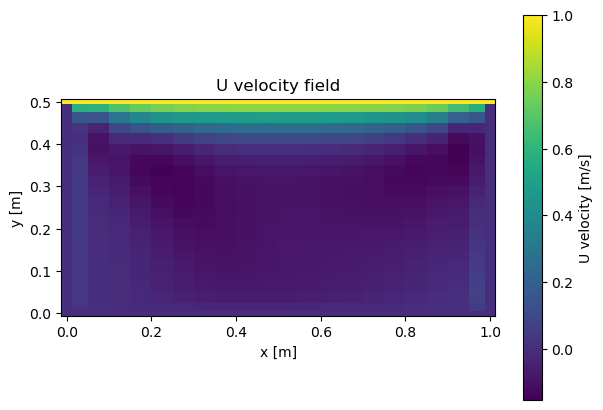

[[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  1.00000000e+00]
 [ 0.00000000e+00  1.97145448e-02  2.90841274e-02  2.99650654e-02
   3.05036926e-02  3.16414630e-02  3.33129663e-02  3.53525174e-02
   3.75916899e-02  3.98155506e-02  4.17251464e-02  4.29155938e-02
   4.28693860e-02  4.09544249e-02  3.63932795e-02  2.81960521e-02
   1.57336668e-02  3.45008034e-03  1.95735865e-02  1.55896342e-01
   5.68494588e-01  1.00000000e+00]
 [ 0.00000000e+00  2.62592325e-03  1.50297863e-04 -2.18754586e-03
  -3.30482187e-03 -3.82556989e-03 -4.28843203e-03 -5.14858832e-03
  -6.83922678e-03 -9.84567159e-03 -1.47485559e-02 -2.22204720e-02
  -3.29436960e-02 -4.73802098e-02 -6.52610038e-02 -8.45297660e-02
  -9.9

In [81]:
# Geometry and mesh size
L = 1.0
H1 = 1.0
H2 = 1.0
M = 20
shape = 'rectangular'

X, Y, X_cor, Y_cor = setUpMesh(M, H1, H2, L, shape)
fields = SimpleFields2D(X, Y, X_cor, Y_cor, rho0=1.0, mu0=1.0)

# --- Stencil setup (example) ---
stencil = Stencil2D(X, Y)

# --- Solver objects ---
momentum_solver = MomentumEquationSolver(stencil, X, Y, X_cor, Y_cor)
rhiechow_solver = RhieChowPressureCorrection(stencil, X, Y, X_cor, Y_cor, reference=(1,1,1.0), tol=1e-6, max_inner=551)
pressure_velocity_corrector = PressureVelocityCorrector(stencil, X_cor, Y_cor)
convergence_monitor = ConvergenceMonitor(atol=1e-6, rtol=1e-4, max_it=5000)

# --- Optional: Initialize velocity ---
# fields.U[:, :] = 0.1  

# --- SIMPLE Outer Loop ---
max_outer = 5
for outer_iter in range(max_outer):
    # 1. Solve momentum equations (U-component)
    U, Ap_u, Aw_u, Ae_u, As_u, An_u, Sp_u = momentum_solver.solve(fields, alpha=0.7, component='u')
    fields.U, fields.Ap_u = U, Ap_u

    # (Optional: solve for V-component similarly if you want to track V convergence)
    V, Ap_v, Aw_v, Ae_v, As_v, An_v, Sp_v = momentum_solver.solve(fields, alpha=0.7, component='v')
    fields.V, fields.Ap_v = V, Ap_v

    # 2. Update DpU and DpV for pressure correction (as before)
    fields.DpU = np.zeros_like(Ap_u)
    fields.DpU[1:-1, 1:-1] = 1.0 / (Ap_u[1:-1, 1:-1] + 1e-20)
    fields.DpV = np.zeros_like(Ap_v)
    fields.DpV[1:-1, 1:-1] = 1.0 / (Ap_v[1:-1, 1:-1] + 1e-20)

    # 3. Pressure correction (Rhie–Chow)
    p_prime = rhiechow_solver.solve(fields)
    fields.p_prime = p_prime

    # 4. Apply pressure and velocity correction
    pressure_velocity_corrector.apply(fields, p_prime, alpha_p=0.8)

    # 5. Convergence check on U (x-velocity)
    converged = convergence_monitor.update(Ap_u, Aw_u, Ae_u, As_u, An_u, Sp_u, U)
    if converged:
        print(f"Converged at iteration {outer_iter+1}")
        break

else:
    print("Did not converge within max_outer iterations.")

plt.figure(figsize=(7, 5))
c = plt.pcolormesh(X, Y, fields.U, shading='auto', cmap='viridis')
plt.colorbar(c, label='U velocity [m/s]')
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.title('U velocity field')
plt.gca().set_aspect('equal')
plt.show()

print(fields.U)
print(fields.rho)

